# 01. The problem and the cost model

**Notebook version:** v1.0.0 (2026-10-20) &nbsp;|&nbsp; All numbers are illustrative, not from any real company or process.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## The question
Advanced packaging, such as stacking memory dies into high-bandwidth memory (HBM) or joining chiplets into one package, builds up expensive silicon step by step. Every manufacturer has to decide **how much in-line inspection is enough**.
Check too little and defective units reach customers (field failures, returns, damaged reputation).
Check too much and you pay for the checking itself and slow the line down.

Quality managers call the total of these costs the **cost of quality**. It has three parts:

| Part | Plain meaning | In this model |
|---|---|---|
| Appraisal | Money spent checking | `inspection` and `slowdown` |
| Internal failure | Defects caught before shipping | `scrap` |
| External failure | Defects that reach the customer | `escaped` |

The goal: find the inspection plan with the **lowest total**.

## Our example process
Three assembly steps (surface prep, stack assembly, final integration). At each step a defect can appear, and after each step we can choose what share of units to check.

In [2]:
from src.cost_model import DEFAULTS
p = DEFAULTS
pd.DataFrame({
    "chance a defect appears": p.defect_rate,
    "cost units invested in the unit": p.value_added,
}, index=p.step_names)

,chance a defect appears,cost units invested in the unit
Surface prep,0.020,10.0
Stack assembly,0.030,25.0
Final integration,0.015,40.0


In [3]:
print(f"Chance an inspection spots an existing defect: {p.detection_rate:.0%}")
print(f"Cost of one inspection:      {p.inspection_cost} cost units")
print(f"Slowdown cost per inspection: {p.delay_cost}")
print(f"Cost when a defective unit reaches a customer: {p.escape_cost} cost units")

Chance an inspection spots an existing defect: 90%
Cost of one inspection:      2.0 cost units
Slowdown cost per inspection: 1.0
Cost when a defective unit reaches a customer: 500.0 cost units


## Two extreme plans
A **plan** says what share of units to check after each step. Here are the two extremes, calculated exactly (no randomness yet).

In [4]:
from src.cost_model import expected_cost_analytic, COMPONENTS
plans = {"Check nothing": (0, 0, 0), "Check everything": (1, 1, 1)}
rows = {name: expected_cost_analytic(pl, p) for name, pl in plans.items()}
table = pd.DataFrame(rows).T[list(COMPONENTS) + ["total"]].round(2)
table

,inspection,slowdown,scrap,escaped,total
Check nothing,0.00,0.00,0.00,31.83,31.83
Check everything,5.87,2.94,2.34,0.87,12.02


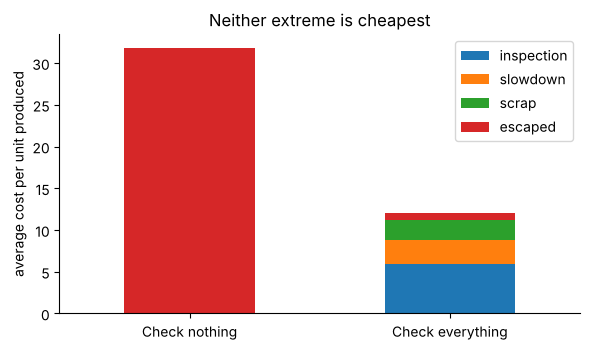

In [5]:
ax = table[list(COMPONENTS)].plot(kind="bar", stacked=True, figsize=(6, 3.6), rot=0)
ax.set_ylabel("average cost per unit produced"); ax.set_title("Neither extreme is cheapest")
plt.tight_layout(); plt.show()

**Reading this:** checking nothing is dominated by the cost of defects reaching customers. Checking everything removes most of that but costs a lot in inspection and slowdown. Somewhere in between is a cheaper plan. Notebook 03 finds it.